Libraries imported successfully!
Dataset downloaded successfully!
Training folders: ['cats', 'dogs']
Validation folders: ['cats', 'dogs']
Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 84ms/step - accuracy: 0.5060 - loss: 0.7077 - val_accuracy: 0.5000 - val_loss: 0.6917
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 76ms/step - accuracy: 0.5610 - loss: 0.6892 - val_accuracy: 0.5740 - val_loss: 0.6673
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.6235 - loss: 0.6552 - val_accuracy: 0.6570 - val_loss: 0.6379
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.6945 - loss: 0.5921 - val_accuracy: 0.6840 - val_loss: 0.6047
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.7340 - loss: 0.5322 - val_accuracy: 0.7050 - val_loss: 0.5722
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.7885 - loss: 0.4654 - val_accuracy: 0.7070 - val_loss: 0.5549
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.7985 - loss: 0.4266 - val_accuracy: 0.7380 - val_loss: 0.5938
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.8580 - loss: 0.3355 - val_accuracy: 0.7370 - 

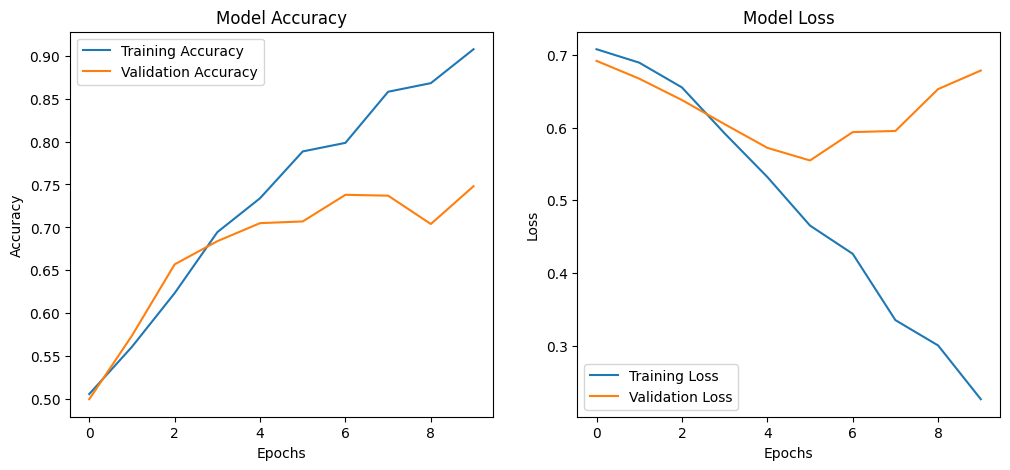

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

DOG VS CAT CLASSIFICATION PROJECT COMPLETED!


In [3]:

# =====================================================
# DOG VS CAT CLASSIFICATION USING CNN
# =====================================================

# 1. IMPORT LIBRARIES

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    Rescaling
)

print("Libraries imported successfully!")

# =====================================================
# 2. DOWNLOAD DATASET
# =====================================================

url = "https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip"

!wget -q {url} -O cats_and_dogs_filtered.zip

# Extract dataset

with zipfile.ZipFile("cats_and_dogs_filtered.zip", "r") as zip_ref:
    zip_ref.extractall(".")

print("Dataset downloaded successfully!")

# Dataset paths

base_dir = "cats_and_dogs_filtered"

train_dir = os.path.join(base_dir, "train")
validation_dir = os.path.join(base_dir, "validation")

print("Training folders:", os.listdir(train_dir))
print("Validation folders:", os.listdir(validation_dir))

# =====================================================
# 3. LOAD DATASET
# =====================================================

IMG_SIZE = (150, 150)
BATCH_SIZE = 32

train_data = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

validation_data = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

# =====================================================
# 4. NORMALIZE IMAGES
# =====================================================

normalization_layer = Rescaling(1./255)

train_data = train_data.map(
    lambda x, y: (normalization_layer(x), y)
)

validation_data = validation_data.map(
    lambda x, y: (normalization_layer(x), y)
)

# Improve data loading performance

AUTOTUNE = tf.data.AUTOTUNE

train_data = train_data.prefetch(AUTOTUNE)
validation_data = validation_data.prefetch(AUTOTUNE)

# =====================================================
# 5. BUILD CNN MODEL
# =====================================================

model = Sequential([

    Input(shape=(150, 150, 3)),

    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),

    Dense(128, activation='relu'),

    Dropout(0.5),

    Dense(1, activation='sigmoid')
])

# Display model architecture

model.summary()

# =====================================================
# 6. COMPILE MODEL
# =====================================================

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# =====================================================
# 7. TRAIN MODEL
# =====================================================

history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=10
)

# =====================================================
# 8. DISPLAY ACCURACY AND LOSS GRAPHS
# =====================================================

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

# =====================================================
# 9. PREDICT YOUR OWN IMAGE
# =====================================================

from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array

uploaded = files.upload()

for filename in uploaded.keys():

    img = load_img(filename, target_size=(150,150))

    img_array = img_to_array(img)

    img_array = img_array / 255.0

    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array)

    plt.imshow(load_img(filename))
    plt.axis('off')
    plt.show()

    if prediction[0][0] > 0.5:

        print("Prediction: DOG 🐶")
        print("Confidence:", round(float(prediction[0][0]) * 100, 2), "%")

    else:

        print("Prediction: CAT 🐱")
        print("Confidence:", round((1-float(prediction[0][0])) * 100, 2), "%")

# =====================================================
# 10. SAVE TRAINED MODEL
# =====================================================

model.save("dog_cat_classifier.keras")

print("Model saved successfully!")

# Download trained model

files.download("dog_cat_classifier.keras")

# =====================================================
# PROJECT COMPLETED
# =====================================================

print("DOG VS CAT CLASSIFICATION PROJECT COMPLETED!")


Image 1: Actual = DOG, Predicted = DOG, Confidence = 99.19%
Image 2: Actual = CAT, Predicted = CAT, Confidence = 68.86%
Image 3: Actual = DOG, Predicted = DOG, Confidence = 86.84%
Image 4: Actual = CAT, Predicted = DOG, Confidence = 76.76%
Image 5: Actual = DOG, Predicted = DOG, Confidence = 58.19%
Image 6: Actual = CAT, Predicted = DOG, Confidence = 71.45%
Image 7: Actual = CAT, Predicted = CAT, Confidence = 76.38%
Image 8: Actual = DOG, Predicted = DOG, Confidence = 62.37%
Image 9: Actual = CAT, Predicted = CAT, Confidence = 99.63%
Image 10: Actual = DOG, Predicted = DOG, Confidence = 94.31%


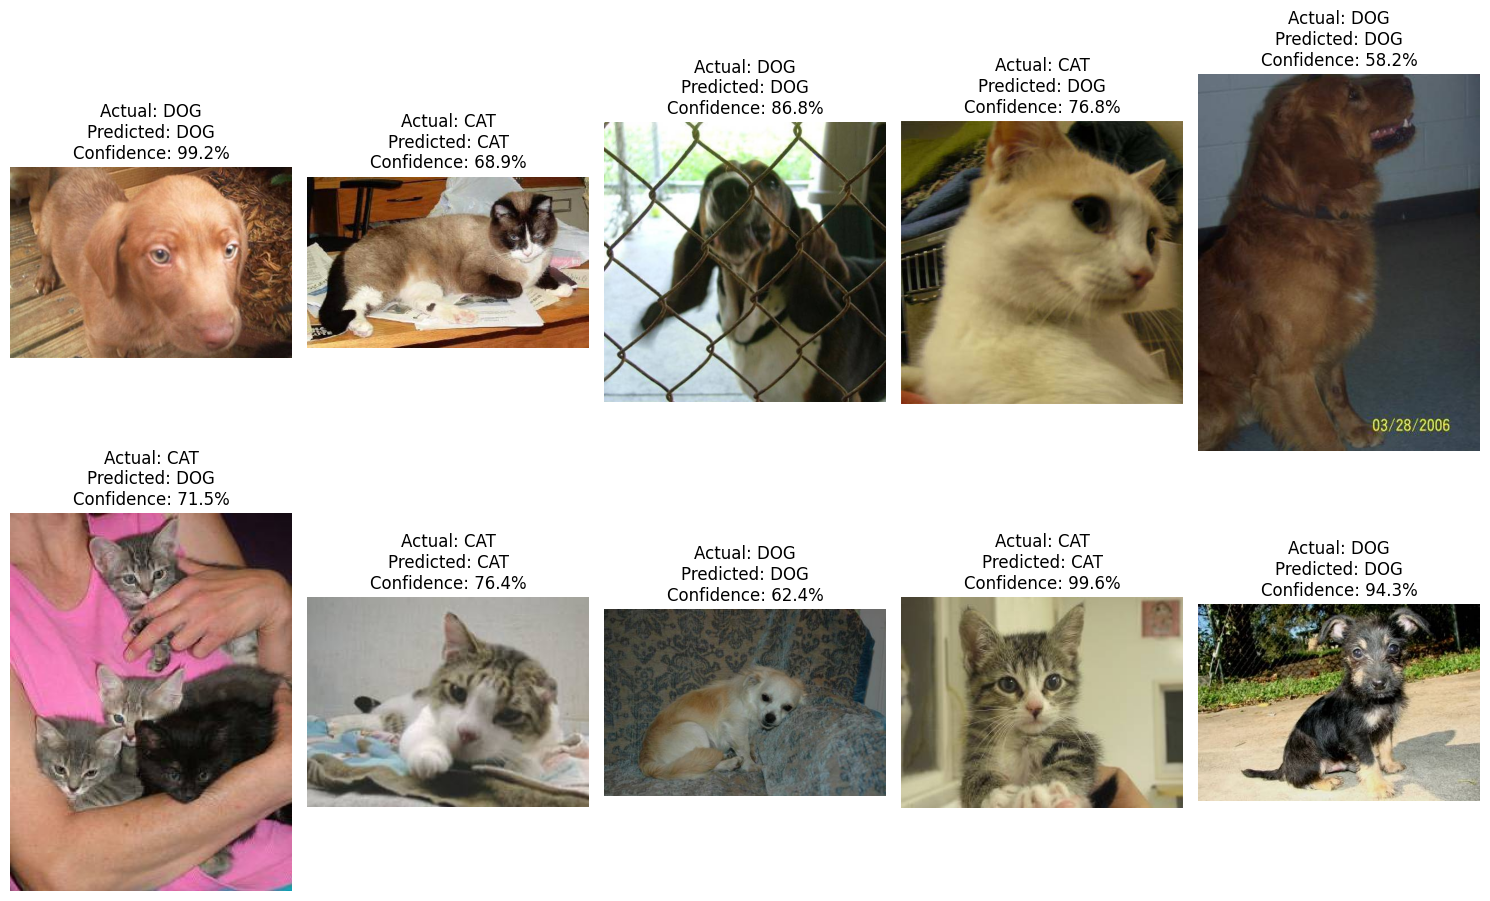

In [4]:

import os
import random
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.utils import load_img, img_to_array

# 1. Get dog and cat image folders

cat_dir = os.path.join(validation_dir, "cats")
dog_dir = os.path.join(validation_dir, "dogs")

# 2. Select 5 random images from each folder

cat_images = random.sample(
    os.listdir(cat_dir), 5
)

dog_images = random.sample(
    os.listdir(dog_dir), 5
)

# 3. Combine both image lists

test_images = []

for filename in cat_images:
    test_images.append((os.path.join(cat_dir, filename), "CAT"))

for filename in dog_images:
    test_images.append((os.path.join(dog_dir, filename), "DOG"))

# Shuffle images

random.shuffle(test_images)

# 4. Predict all 10 images

plt.figure(figsize=(15, 10))

for i, (image_path, actual_label) in enumerate(test_images):

    # Load image
    img = load_img(image_path, target_size=(150, 150))

    # Convert into array
    img_array = img_to_array(img)

    # Normalize
    img_array = img_array / 255.0

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    prediction = model.predict(img_array, verbose=0)

    # Identify dog or cat
    if prediction[0][0] > 0.5:
        predicted_label = "DOG"
        confidence = prediction[0][0] * 100
    else:
        predicted_label = "CAT"
        confidence = (1 - prediction[0][0]) * 100

    # Display image
    plt.subplot(2, 5, i + 1)
    plt.imshow(load_img(image_path))
    plt.axis("off")

    plt.title(
        f"Actual: {actual_label}\n"
        f"Predicted: {predicted_label}\n"
        f"Confidence: {confidence:.1f}%"
    )

    # Print result
    print(
        f"Image {i+1}: Actual = {actual_label}, "
        f"Predicted = {predicted_label}, "
        f"Confidence = {confidence:.2f}%"
    )

plt.tight_layout()
plt.show()
